# 6. Unsupervised Learning: Drug Safety-Profile Clusters

**Input:** the clean long tables from notebook 2 (`data/clean/case_ingredients/`, `case_reactions/`) and the case
table (only for flags, and, after clustering, the outcome).
**Output:** one row per drug with its cluster (`data/unsupervised/drug_clusters.parquet`), tables in
`reports/tables/`, figures in `reports/figures/`.

**Question:** which suspect ingredients are reported with similar reactions? Each drug is described by the
reactions listed on the cases where it is a suspect. Drugs with similar descriptions are grouped. The groups are
**reporting patterns**, not proof that a drug causes a reaction: FAERS has no count of people who took a drug
without reporting anything.

| Section | What it does |
|---|---|
| 1 | Load, keep the clustering population, drop outcome terms |
| 2 | Count drug x reaction pairs |
| 3 | Three representations: reaction share, TF-IDF, PPMI |
| 4 | Two methods: k-means and hierarchical (agglomerative) clustering |
| 5 | Choose k: silhouette, Davies-Bouldin, cluster balance, bootstrap stability |
| 6 | Compare representations and methods |
| 7 | What is in each cluster |
| 8 | Visualizations |
| 9 | After clustering: seriousness and time trends per cluster |
| 10 | Sensitivity analysis |
| 11 | Save |

This notebook extends Orko Mookerjee's first clustering notebook (`archive/original_notebooks/`), which used
reaction-share profiles and k-means only. Its result is kept as the reference row in section 6.

## 1. Setup and load

- **Population:** all cleaned cases except *mass reports* (groups of more than 5 identical, templated reports,
  notebook 2), which would make one lawsuit look like a drug's safety profile.
- **Outcome terms removed:** `DEATH` and `HOSPITALISATION` restate the supervised target. Removing them keeps the
  clusters free of the outcome, so that the comparison of seriousness across clusters in section 9 is fair.
- The outcome itself is not loaded until section 9.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import umap
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
import warnings

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
OUT_DIR = PROJECT_ROOT / "data" / "unsupervised"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for folder in (OUT_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.dpi"] = 110

N_DRUGS, N_REACTIONS = 500, 1000              # main vocabulary
MAX_DRUGS, MAX_REACTIONS = 800, 2000          # counted once, so section 10 can test other sizes
OUTCOME_TERMS = {"DEATH", "HOSPITALISATION"}
K_RANGE = range(4, 31)
SVD_DIMS = 50
RANDOM_STATE = 0
rng = np.random.default_rng(RANDOM_STATE)
# NumPy 2 with Apple's Accelerate BLAS raises false "divide by zero ... in matmul" warnings; values are checked below
warnings.filterwarnings("ignore", message=".*encountered in matmul")
threadpool_limits(1)  # 500 drugs is tiny: one thread per k-means fit is faster than many fighting over cores

cases = pd.read_parquet(CLEAN_DIR / "reports_clean.parquet", columns=["safetyreportid", "quarter", "is_mass_report"])
keep_ids = cases.loc[~cases["is_mass_report"], "safetyreportid"]
ingredients = pq.read_table(CLEAN_DIR / "case_ingredients", read_dictionary=["ingredient"]).to_pandas()
reactions = pq.read_table(CLEAN_DIR / "case_reactions", read_dictionary=["reaction_pt"]).to_pandas()
ingredients = ingredients[ingredients["safetyreportid"].isin(keep_ids)]
reactions = reactions[reactions["safetyreportid"].isin(keep_ids) & ~reactions["reaction_pt"].isin(OUTCOME_TERMS)]
print(f"cases kept: {len(keep_ids):,} of {len(cases):,} (mass reports dropped)")
print(f"ingredient rows: {len(ingredients):,}, reaction rows: {len(reactions):,}")

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cases kept: 8,362,456 of 8,477,316 (mass reports dropped)
ingredient rows: 13,883,686, reaction rows: 24,886,511


## 2. Drug x reaction counts

Entry (i, j) = evidence that drug i is reported with reaction j. Drugs and reactions are ranked by how many cases
mention them. The pairs are formed in 10 slices of case ids so that a case with many drugs and many reactions never
needs a huge table at once.

**One case, one share of evidence per drug.** A plain count lets a few very large reports dominate: 1% of cases
(more than 10 suspect drugs or 30 reactions) produce 40% of all drug-reaction pairs, and about 4,600 templated
Canadian reports with a median of 27 drugs and 49 reactions produce 13% on their own. Their reactions (e.g.
`ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE`) then define the profile of every common drug they list.
So each pair is weighted by 1 / (number of suspect ingredients on the case): a case's evidence is split among
its suspect drugs. The plain count is kept for the sensitivity check in section 10.

In [2]:
drug_cases = ingredients["ingredient"].value_counts()
reaction_cases = reactions["reaction_pt"].value_counts()
drug_vocab = pd.Index(drug_cases.index[:MAX_DRUGS].astype(str))
reaction_vocab = pd.Index(reaction_cases.index[:MAX_REACTIONS].astype(str))
print(f"distinct ingredients: {len(drug_cases):,}; top {N_DRUGS} cover "
      f"{drug_cases.iloc[:N_DRUGS].sum() / drug_cases.sum():.1%} of ingredient mentions")
print(f"distinct reaction terms: {len(reaction_cases):,}; top {N_REACTIONS} cover "
      f"{reaction_cases.iloc[:N_REACTIONS].sum() / reaction_cases.sum():.1%} of reaction mentions")

ing = ingredients.assign(d=drug_vocab.get_indexer(ingredients["ingredient"].astype(str)))
ing = ing.loc[ing["d"] >= 0, ["safetyreportid", "d"]]
rxn = reactions.assign(r=reaction_vocab.get_indexer(reactions["reaction_pt"].astype(str)))
rxn = rxn.loc[rxn["r"] >= 0, ["safetyreportid", "r"]]

n_suspect = ingredients.groupby("safetyreportid").size()  # all suspect ingredients, not only the vocabulary
ing["weight"] = 1.0 / n_suspect.reindex(ing["safetyreportid"]).to_numpy()

counts_full = np.zeros((MAX_DRUGS, MAX_REACTIONS))      # weighted evidence (main)
raw_counts_full = np.zeros((MAX_DRUGS, MAX_REACTIONS))  # plain case counts (section 10)
for part in range(10):
    pairs = ing[ing["safetyreportid"] % 10 == part].merge(rxn[rxn["safetyreportid"] % 10 == part], on="safetyreportid")
    flat = pairs["d"].to_numpy() * MAX_REACTIONS + pairs["r"].to_numpy()
    size = MAX_DRUGS * MAX_REACTIONS
    counts_full += np.bincount(flat, weights=pairs["weight"].to_numpy(), minlength=size).reshape(MAX_DRUGS, MAX_REACTIONS)
    raw_counts_full += np.bincount(flat, minlength=size).reshape(MAX_DRUGS, MAX_REACTIONS)
print(f"pairs counted: {raw_counts_full.sum():,.0f}; weighted evidence: {counts_full.sum():,.0f}")

counts = counts_full[:N_DRUGS, :N_REACTIONS]
drugs, reaction_names = drug_vocab[:N_DRUGS], reaction_vocab[:N_REACTIONS]
print("main count matrix:", counts.shape, f"{(counts > 0).mean():.1%} non-zero")

distinct ingredients: 7,183; top 500 cover 85.4% of ingredient mentions
distinct reaction terms: 21,654; top 1000 cover 84.7% of reaction mentions


pairs counted: 56,625,078; weighted evidence: 21,511,799
main count matrix: (500, 1000) 81.7% non-zero


## 3. Three representations of a drug

| Name | Each entry | What it emphasizes |
|---|---|---|
| **share** (reference) | count / drug's total | how a drug's reports are spread; dominated by terms every drug has (`DRUG INEFFECTIVE`, `FATIGUE`) |
| **TF-IDF** | log(1 + evidence) x (1 + log(n_drugs / drugs with that reaction)), rows unit length | reactions that are frequent for this drug **and** rare across drugs |
| **PPMI** | max(0, log(observed / expected)), expected = row total x column total / grand total | disproportionality, the idea behind the proportional reporting ratio (PRR) used in pharmacovigilance |

PPMI uses entries with evidence of 3 or more only, so a single report cannot create a strong signal. Each representation is
reduced to 50 dimensions with truncated SVD and scaled to unit length, so that Euclidean k-means on the result
behaves like clustering by cosine similarity.

In [3]:
def share_rep(c):
    return c / c.sum(axis=1, keepdims=True)


def tfidf_rep(c):
    # log(1 + count), not sklearn's sublinear 1 + log(count), which turns negative for fractional evidence below 1
    idf = np.log((1 + len(c)) / (1 + (c > 0).sum(axis=0))) + 1
    return normalize(np.log1p(c) * idf)


def ppmi_rep(c, min_count: int = 3):
    expected = c.sum(axis=1, keepdims=True) * c.sum(axis=0, keepdims=True) / c.sum()
    pmi = np.log((c + 0.5) / (expected + 0.5))
    pmi[c < min_count] = 0
    return normalize(np.maximum(pmi, 0))


def embed(rep, dims: int = SVD_DIMS, seed: int = RANDOM_STATE):
    svd = TruncatedSVD(n_components=dims, random_state=seed).fit(rep)
    return normalize(svd.transform(rep)), svd.explained_variance_ratio_.sum()


REPRESENTATIONS = {"share": share_rep, "TF-IDF": tfidf_rep, "PPMI": ppmi_rep}
reps = {name: f(counts.astype(float)) for name, f in REPRESENTATIONS.items()}
embeddings = {}
for name, rep in reps.items():
    embeddings[name], var = embed(rep)
    assert np.isfinite(embeddings[name]).all()
    print(f"{name:7s}: {SVD_DIMS} SVD dimensions keep {var:.1%} of the variance")

share  : 50 SVD dimensions keep 82.7% of the variance
TF-IDF : 50 SVD dimensions keep 77.5% of the variance


PPMI   : 50 SVD dimensions keep 68.5% of the variance


## 4. Two clustering methods

| Method | Mechanism | Hyperparameters explored |
|---|---|---|
| **k-means** | partitions drugs around k centroids, minimizing within-cluster squared distance | k; 20 random starts each |
| **Agglomerative (hierarchical)** | starts with every drug alone and repeatedly merges the closest pair of groups | k; linkage (average, complete, Ward) |

They fail in different ways: k-means prefers round clusters of similar size and depends on the starting points;
hierarchical clustering is deterministic and gives a full tree, but average linkage tends to "chain" into one large
group. With 500 drugs both run on the full data, so no subsample is needed.

In [4]:
def kmeans_labels(Z, k, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(Z)


def agglo_labels(Z, k, linkage_name="ward"):
    if linkage_name == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    return AgglomerativeClustering(n_clusters=k, metric="cosine", linkage=linkage_name).fit_predict(Z)


def cluster_quality(Z, labels) -> dict:
    sizes = np.bincount(labels)
    share = sizes / sizes.sum()
    return {"silhouette": silhouette_score(Z, labels, metric="cosine"),
            "davies_bouldin": davies_bouldin_score(Z, labels),
            "calinski_harabasz": calinski_harabasz_score(Z, labels),
            "largest_cluster_share": share.max(),
            "n_tiny_clusters": int((sizes < 3).sum()),
            "size_entropy": float(-(share * np.log(share)).sum() / np.log(len(sizes)))}


def bootstrap_stability(Z, k, method, n_boot: int = 10) -> float:
    """Mean ARI between the full-data labels and labels refit on random 80% subsets (same drugs compared)."""
    full = method(Z, k)
    aris = []
    for b in range(n_boot):
        rows = np.random.default_rng(100 + b).choice(len(Z), int(0.8 * len(Z)), replace=False)
        aris.append(adjusted_rand_score(full[rows], method(Z[rows], k)))
    return float(np.mean(aris))

## 5. Choosing k

For every k from 4 to 30, each method is scored on four criteria:

- **Silhouette** (cosine, -1 to 1, higher is better): is each drug closer to its own cluster than to the next one?
- **Davies-Bouldin** (lower is better): average similarity of each cluster to its most similar other cluster.
- **Largest cluster share / tiny clusters:** a solution with one cluster holding 90% of the drugs has a fine
  silhouette and no use.
- **Bootstrap stability:** adjusted Rand index (ARI) between the full-data clustering and clusterings refit on
  random 80% subsets. 1 = identical, 0 = chance agreement.

First the linkage for hierarchical clustering, on TF-IDF.

In [5]:
Z = embeddings["TF-IDF"]
linkage_rows = []
for name in ("average", "complete", "ward"):
    for k in (8, 12, 16, 20):
        linkage_rows.append({"linkage": name, "k": k, **cluster_quality(Z, agglo_labels(Z, k, name))})
linkage_table = pd.DataFrame(linkage_rows)
linkage_table.to_csv(TABLE_DIR / "unsup_linkage_comparison.csv", index=False)
display(linkage_table.round(3))

,linkage,k,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,n_tiny_clusters,size_entropy
0,average,8,0.348,0.838,10.035,0.948,3,0.140
1,average,12,0.233,0.989,8.646,0.920,5,0.182
2,average,16,0.172,1.088,15.212,0.720,6,0.399
3,average,20,0.156,1.070,13.437,0.694,8,0.417
4,complete,8,0.184,1.483,25.233,0.538,0,0.541
5,complete,12,0.176,1.321,20.839,0.504,2,0.522
6,complete,16,0.175,1.381,23.812,0.334,4,0.674
7,complete,20,0.164,1.509,21.841,0.264,4,0.732
8,ward,8,0.191,2.001,39.947,0.260,0,0.902
9,ward,12,0.191,1.883,36.477,0.158,0,0.928


Average linkage "chains": at k = 8 one cluster holds 95% of the drugs. Complete linkage still leaves a quarter to a
half of the drugs in one cluster, plus tiny clusters. Ward linkage gives balanced groups with no tiny clusters and,
from k = 8 up, the best silhouette of the three. The rest of the notebook uses Ward linkage.

In [6]:
k_rows = []
for rep_name, Zr in embeddings.items():
    for k in K_RANGE:
        for method_name, method in (("k-means", kmeans_labels), ("agglomerative", agglo_labels)):
            labels = method(Zr, k)
            k_rows.append({"representation": rep_name, "method": method_name, "k": k, **cluster_quality(Zr, labels),
                           "stability_ari": bootstrap_stability(Zr, k, method, n_boot=5)})
    print("done:", rep_name)
k_table = pd.DataFrame(k_rows)
k_table.to_csv(TABLE_DIR / "unsup_k_selection.csv", index=False)
display(k_table.query("representation == 'TF-IDF'").round(3).head(54))

done: share


done: TF-IDF


done: PPMI


,representation,method,k,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,n_tiny_clusters,size_entropy,stability_ari
54,TF-IDF,k-means,4,0.199,2.292,61.279,0.378,0,0.968,0.888
55,TF-IDF,agglomerative,4,0.165,2.232,52.287,0.492,0,0.883,0.729
56,TF-IDF,k-means,5,0.212,2.063,55.049,0.350,0,0.924,0.853
57,TF-IDF,agglomerative,5,0.154,2.279,47.458,0.340,0,0.950,0.561
58,TF-IDF,k-means,6,0.241,1.955,52.250,0.336,0,0.900,0.839
59,TF-IDF,agglomerative,6,0.172,1.983,43.875,0.340,0,0.872,0.511
60,TF-IDF,k-means,7,0.221,2.066,48.267,0.224,0,0.940,0.686
61,TF-IDF,agglomerative,7,0.184,1.930,41.674,0.260,0,0.898,0.497
62,TF-IDF,k-means,8,0.189,2.090,45.560,0.176,0,0.979,0.776
63,TF-IDF,agglomerative,8,0.191,2.001,39.947,0.260,0,0.902,0.447


**Rule for k.** Among solutions where no cluster holds more than 25% of the drugs and stability ARI is at least
0.5, take the k with the highest silhouette. Ties in spirit (silhouette within 0.005) go to the smaller k, which is
easier to read. The search stops at k = 30 on purpose: about 17 drugs per cluster, roughly the size of a
therapeutic class. Silhouette is still creeping up at 30 for every representation (next cell): drug safety profiles
form nested groups rather than one natural number of clusters (see the dendrogram in section 8), so the cap is a
readability choice, and section 10 checks k = 26-34.

In [7]:
def choose_k(table: pd.DataFrame) -> int:
    ok = table[(table["largest_cluster_share"] <= 0.25) & (table["stability_ari"] >= 0.5)]
    if ok.empty:
        ok = table
    top = ok["silhouette"].max()
    return int(ok.loc[ok["silhouette"] >= top - 0.005, "k"].min())


chosen = {(r, m): choose_k(part) for (r, m), part in k_table.groupby(["representation", "method"])}
display(pd.Series(chosen, name="chosen k").to_frame())

chosen k
PPMI   agglomerative        30
       k-means              29
TF-IDF agglomerative        30
       k-means              30
share  agglomerative        29
       k-means              30

## 6. Representations x methods

Each combination at its chosen k, with 20-seed bootstrap stability. The reference row is the original notebook's
setting: reaction-share profiles, k-means, k picked by the best silhouette between 4 and 12.

In [8]:
summary_rows = []
for (rep_name, method_name), k in chosen.items():
    Zr = embeddings[rep_name]
    method = kmeans_labels if method_name == "k-means" else agglo_labels
    labels = method(Zr, k)
    summary_rows.append({"representation": rep_name, "method": method_name, "k": k, **cluster_quality(Zr, labels),
                         "stability_ari": bootstrap_stability(Zr, k, method, n_boot=20)})

ref = k_table.query("representation == 'share' and method == 'k-means' and k <= 12")
ref_k = int(ref.loc[ref["silhouette"].idxmax(), "k"])
ref_labels = kmeans_labels(embeddings["share"], ref_k)
summary_rows.append({"representation": "share (original nb, best silhouette k<=12)", "method": "k-means", "k": ref_k,
                     **cluster_quality(embeddings["share"], ref_labels),
                     "stability_ari": bootstrap_stability(embeddings["share"], ref_k, kmeans_labels, n_boot=20)})
method_summary = pd.DataFrame(summary_rows)
method_summary.to_csv(TABLE_DIR / "unsup_method_summary.csv", index=False)
display(method_summary.round(3))

,representation,method,k,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,n_tiny_clusters,size_entropy,stability_ari
0,PPMI,agglomerative,30,0.342,1.623,24.629,0.088,0,0.954,0.670
1,PPMI,k-means,29,0.373,1.513,26.300,0.104,0,0.958,0.691
2,TF-IDF,agglomerative,30,0.263,1.497,28.066,0.102,0,0.924,0.724
3,TF-IDF,k-means,30,0.274,1.560,28.367,0.084,0,0.944,0.571
4,share,agglomerative,29,0.303,1.729,24.684,0.076,0,0.949,0.647
5,share,k-means,30,0.327,1.638,25.385,0.078,0,0.950,0.633
6,"share (original nb, best silhouette k<=12)",k-means,12,0.232,2.075,31.910,0.138,0,0.964,0.625


Silhouette values are not comparable **across** representations (each lives in its own space), so silhouette picks
k **within** a representation. Across representations we compare balance, bootstrap stability (ARI is comparable)
and readability:

- All three keep the largest cluster near 10% of drugs once each case's evidence is split among its drugs
  (section 2). The original notebook's single giant cluster (380 of 400 drugs at k = 4) came from plain counts on
  the uncleaned lists; with weighted counts even the share profiles split into usable groups (reference row).
- Stability is mixed: on TF-IDF, Ward clustering is the most stable solution of all (ARI about 0.72) while k-means
  is the least (about 0.57); on PPMI both are about 0.67-0.69.
- TF-IDF is used for the main analysis because its weights explain each cluster directly (the characteristic
  reactions in section 7 are the highest TF-IDF terms) and both methods give readable groups on it.

**k-means is the main method** even though Ward is more stable here: k-means has centroids, so a new drug (or a
drug whose profile changes next quarter) can be assigned to the nearest cluster without refitting, which the
pipeline in notebook 7 needs. Ward clustering is the check that the groups are not an artifact of one algorithm.

In [9]:
MAIN_REP = "TF-IDF"
Z = embeddings[MAIN_REP]
K_KM, K_AG = chosen[(MAIN_REP, "k-means")], chosen[(MAIN_REP, "agglomerative")]
km_labels = kmeans_labels(Z, K_KM)
ag_labels = agglo_labels(Z, K_AG)
print(f"k-means k={K_KM}, agglomerative k={K_AG}; agreement ARI = {adjusted_rand_score(km_labels, ag_labels):.3f}")

k-means k=30, agglomerative k=30; agreement ARI = 0.562


## 7. What is in each cluster

For each k-means cluster: its size, the drugs reported in the most cases, and the reactions that **characterize**
it (highest average TF-IDF weight among its drugs, so common-everywhere terms rank low). The label is the top three
characteristic reactions; a short clinical name is added in the report.

In [10]:
tfidf = reps[MAIN_REP]
n_cases_per_drug = drug_cases.reindex(drugs).to_numpy()


def describe_clusters(labels) -> pd.DataFrame:
    rows = []
    for c in np.unique(labels):
        members = np.flatnonzero(labels == c)
        by_size = members[np.argsort(-n_cases_per_drug[members])]
        weight = tfidf[members].mean(axis=0)
        top_rx = reaction_names[np.argsort(-weight)[:8]]
        rows.append({"cluster": int(c), "n_drugs": len(members), "n_case_mentions": int(n_cases_per_drug[members].sum()),
                     "label": " / ".join(top_rx[:3]), "top_drugs": " | ".join(drugs[by_size[:8]]),
                     "characteristic_reactions": " | ".join(top_rx)})
    return pd.DataFrame(rows).sort_values("n_case_mentions", ascending=False)


km_profile = describe_clusters(km_labels)
ag_profile = describe_clusters(ag_labels)
km_profile.to_csv(TABLE_DIR / "unsup_kmeans_clusters.csv", index=False)
ag_profile.to_csv(TABLE_DIR / "unsup_agglomerative_clusters.csv", index=False)
display(km_profile)

,cluster,n_drugs,n_case_mentions,label,top_drugs,characteristic_reactions
16,16,36,1808323,NEEDLE ISSUE / DRUG INEFFECTIVE / INJECTION SITE PAIN,DUPILUMAB | ADALIMUMAB | SECUKINUMAB | ETANERCEPT | EVOLOCUMAB | ABATACEPT | RISANKIZU...,NEEDLE ISSUE | DRUG INEFFECTIVE | INJECTION SITE PAIN | PRODUCT DOSE OMISSION ISSUE | ...
2,2,25,1220183,DRUG INEFFECTIVE / ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE / OFF LABEL USE,METHOTREXATE | RITUXIMAB | PREDNISONE | TOFACITINIB | INFLIXIMAB | UPADACITINIB | TOCI...,DRUG INEFFECTIVE | ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE | OFF LABEL USE...
13,13,33,1055306,ACUTE KIDNEY INJURY / DRUG INEFFECTIVE / DIZZINESS,RANITIDINE | VALSARTAN | METFORMIN | ASPIRIN | AMLODIPINE | PANTOPRAZOLE | ATORVASTATI...,ACUTE KIDNEY INJURY | DRUG INEFFECTIVE | DIZZINESS | DYSPNOEA | FATIGUE | NAUSEA | HYP...
8,8,39,787551,FEBRILE NEUTROPENIA / MYELOSUPPRESSION / OFF LABEL USE,CYCLOPHOSPHAMIDE | CARBOPLATIN | DOXORUBICIN | PACLITAXEL | VINCRISTINE | OXALIPLATIN ...,FEBRILE NEUTROPENIA | MYELOSUPPRESSION | OFF LABEL USE | NEUTROPENIA | PYREXIA | CYTOK...
27,27,23,785088,OFF LABEL USE / FATIGUE / DRUG INEFFECTIVE,LENALIDOMIDE | DEXAMETHASONE | PEMBROLIZUMAB | POMALIDOMIDE | TACROLIMUS | NIVOLUMAB |...,OFF LABEL USE | FATIGUE | DRUG INEFFECTIVE | DIARRHOEA | PNEUMONIA | NAUSEA | COVID-19...
23,23,15,770185,DRUG WITHDRAWAL SYNDROME NEONATAL / DEPENDENCE / LEARNING DISABILITY,ACETAMINOPHEN | OXYCODONE | HYDROCODONE | MORPHINE | TRAMADOL | HYDROMORPHONE | BUPREN...,DRUG WITHDRAWAL SYNDROME NEONATAL | DEPENDENCE | LEARNING DISABILITY | DRUG DEPENDENCE...
19,19,42,748356,DRUG INEFFECTIVE / INTENTIONAL OVERDOSE / POISONING DELIBERATE,CLOZAPINE | PREGABALIN | QUETIAPINE | LEVETIRACETAM | GABAPENTIN | SERTRALINE | RISPER...,DRUG INEFFECTIVE | INTENTIONAL OVERDOSE | POISONING DELIBERATE | OFF LABEL USE | TOXIC...
1,1,35,572925,FATIGUE / MALIGNANT NEOPLASM PROGRESSION / DIARRHOEA,PALBOCICLIB | BEVACIZUMAB | CAPECITABINE | TRASTUZUMAB | CABOZANTINIB | DOCETAXEL | LE...,FATIGUE | MALIGNANT NEOPLASM PROGRESSION | DIARRHOEA | NAUSEA | OFF LABEL USE | PALMAR...
17,17,16,445509,DIARRHOEA / DRUG INEFFECTIVE / NAUSEA,TIRZEPATIDE | SEMAGLUTIDE | INSULIN GLARGINE | DULAGLUTIDE | INSULIN LISPRO | PANCRELI...,DIARRHOEA | DRUG INEFFECTIVE | NAUSEA | BLOOD GLUCOSE INCREASED | WEIGHT DECREASED | O...
14,14,22,430263,DIARRHOEA / DYSPNOEA / OFF LABEL USE,APIXABAN | SACUBITRIL | RIVAROXABAN | MACITENTAN | VOXELOTOR | PIRFENIDONE | AMBRISENT...,DIARRHOEA | DYSPNOEA | OFF LABEL USE | FATIGUE | NAUSEA | DIZZINESS | HEADACHE | PRODU...


## 8. Visualizations

UMAP squeezes the 50 SVD dimensions into 2 for plotting only; distances in the picture are approximate, and no
result depends on it. The same layout is colored by each method.

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


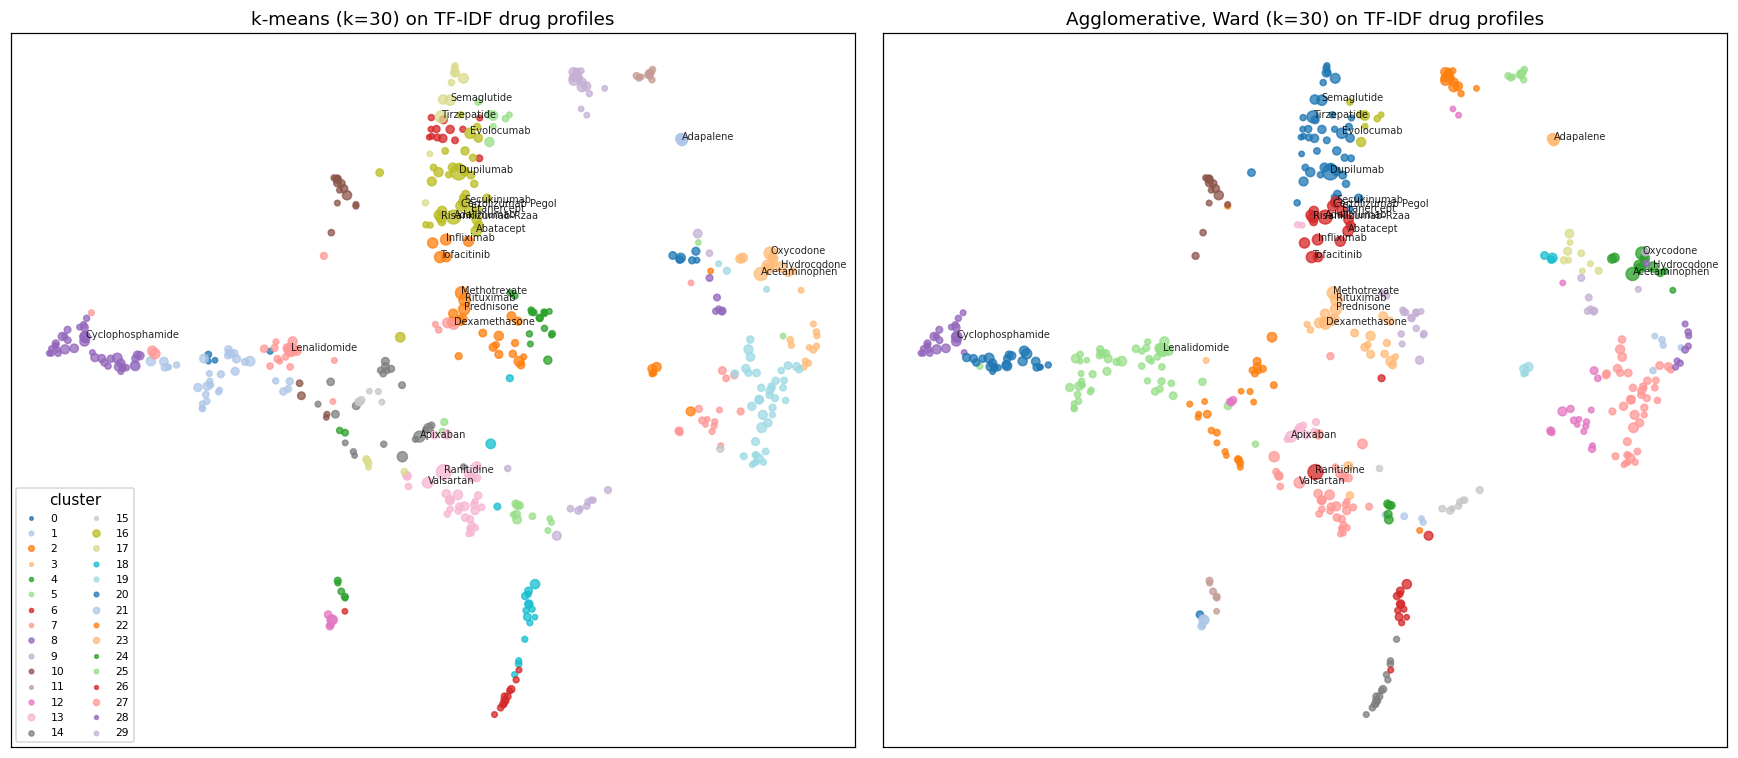

In [11]:
layout = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=RANDOM_STATE).fit_transform(Z)
cmap = plt.get_cmap("tab20")


def scatter(ax, labels, title, annotate: int = 25):
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(layout[m, 0], layout[m, 1], s=np.clip(np.sqrt(n_cases_per_drug[m]) / 6, 4, 120),
                   color=cmap(c % 20), alpha=0.75, label=str(c))
    for i in np.argsort(-n_cases_per_drug)[:annotate]:
        ax.annotate(drugs[i].title()[:18], layout[i], fontsize=6.5, alpha=0.85)
    ax.set(title=title, xticks=[], yticks=[])


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
scatter(axes[0], km_labels, f"k-means (k={K_KM}) on TF-IDF drug profiles")
scatter(axes[1], ag_labels, f"Agglomerative, Ward (k={K_AG}) on TF-IDF drug profiles")
axes[0].legend(title="cluster", fontsize=7, ncol=2, loc="lower left", markerscale=0.6)
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_umap_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

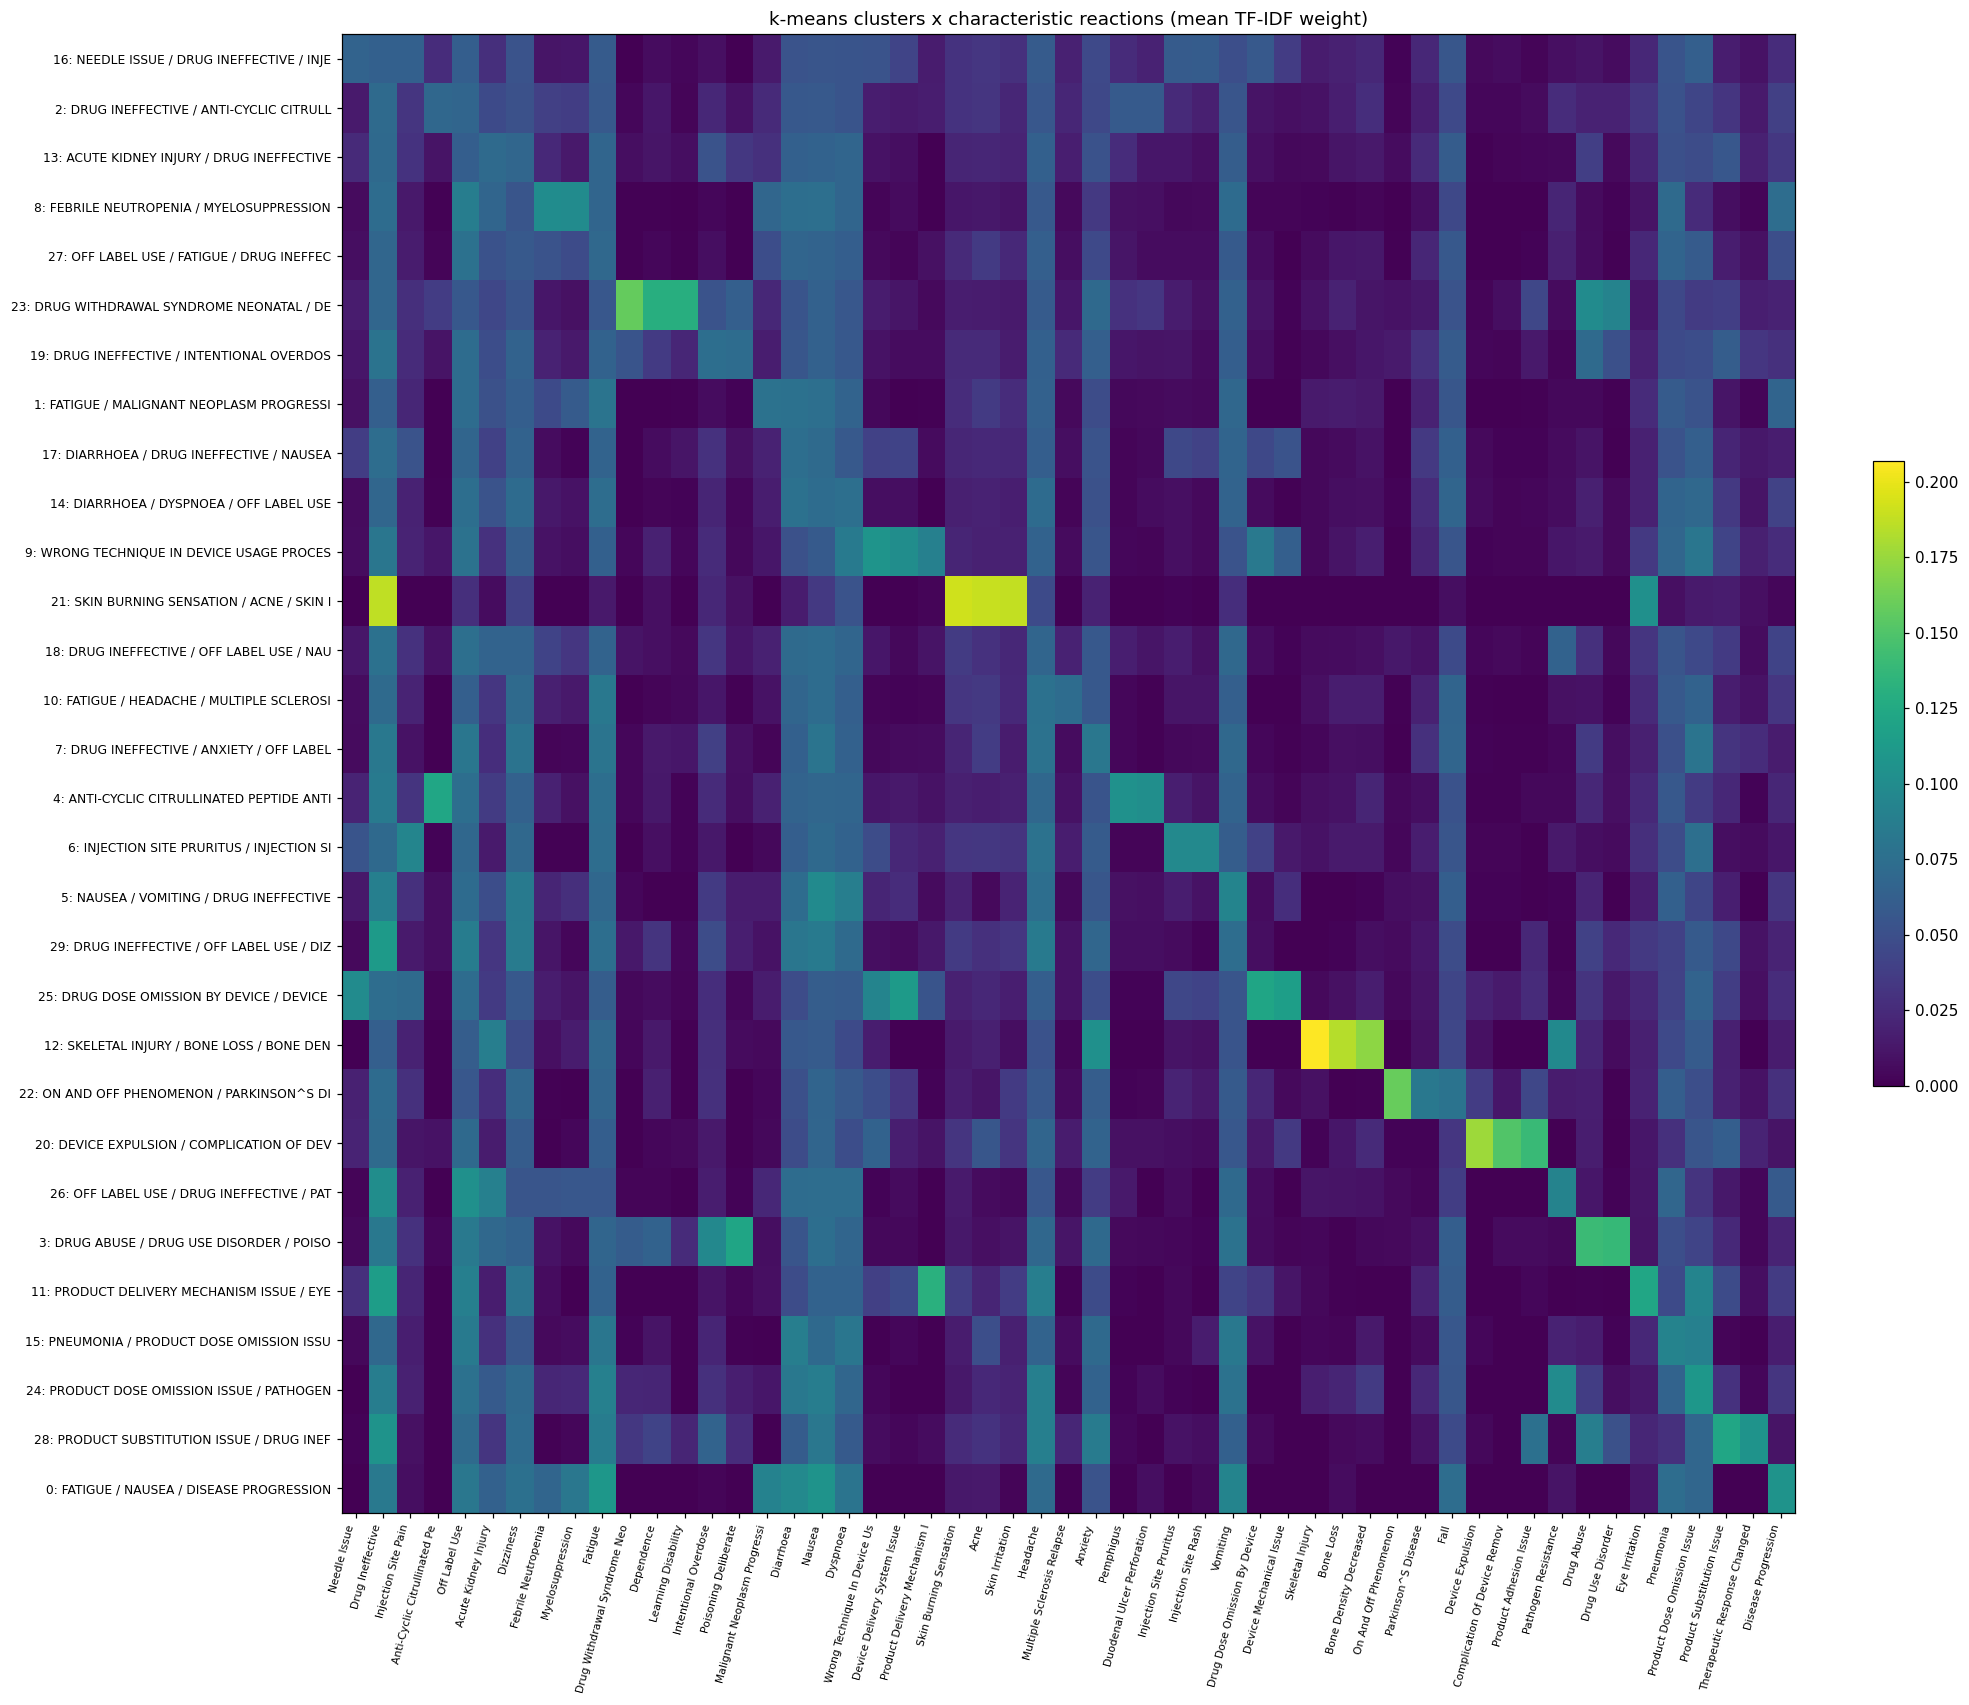

In [12]:
heat_rx = []
for c in km_profile["cluster"]:
    weight = tfidf[km_labels == c].mean(axis=0)
    heat_rx += [r for r in reaction_names[np.argsort(-weight)[:3]] if r not in heat_rx]
heat = pd.DataFrame([tfidf[km_labels == c][:, reaction_names.get_indexer(heat_rx)].mean(axis=0) for c in km_profile["cluster"]],
                    index=[f"{c}: {lab[:38]}" for c, lab in zip(km_profile["cluster"], km_profile["label"])], columns=heat_rx)

fig, ax = plt.subplots(figsize=(18, 0.42 * len(heat) + 3))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heat_rx)), [r.title()[:28] for r in heat_rx], rotation=75, ha="right", fontsize=7)
ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
ax.set_title("k-means clusters x characteristic reactions (mean TF-IDF weight)")
fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_kmeans_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

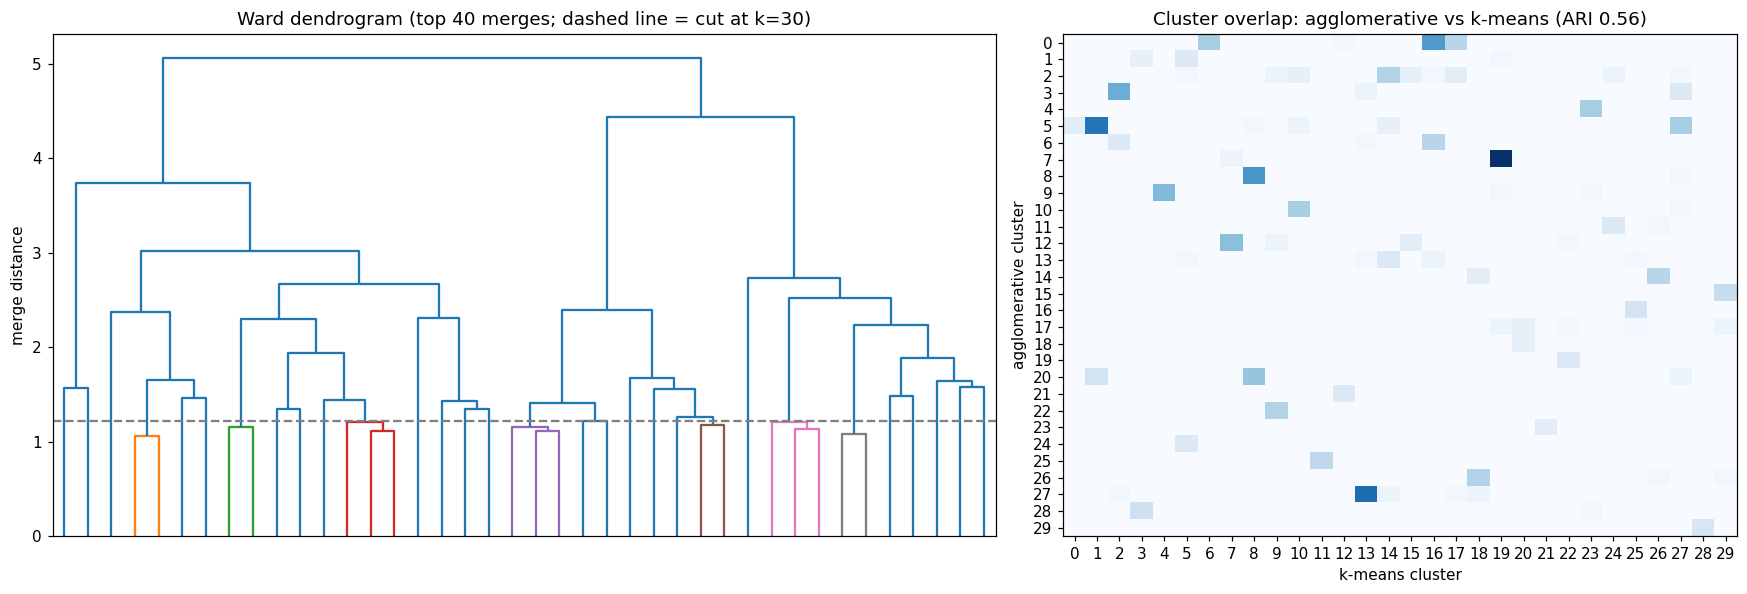

In [13]:
tree = linkage(Z, method="ward")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
cut = tree[-(K_AG - 1), 2]
dendrogram(tree, ax=axes[0], truncate_mode="lastp", p=40, color_threshold=cut, no_labels=True)
axes[0].axhline(cut, color="grey", ls="--")
axes[0].set(title=f"Ward dendrogram (top 40 merges; dashed line = cut at k={K_AG})", ylabel="merge distance")
contingency = pd.crosstab(pd.Series(ag_labels, name="agglomerative"), pd.Series(km_labels, name="k-means"))
axes[1].imshow(contingency.to_numpy(), cmap="Blues", aspect="auto")
axes[1].set(title=f"Cluster overlap: agglomerative vs k-means (ARI {adjusted_rand_score(km_labels, ag_labels):.2f})",
            xlabel="k-means cluster", ylabel="agglomerative cluster",
            xticks=range(contingency.shape[1]), yticks=range(contingency.shape[0]))
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_agglomerative_tree_overlap.png", dpi=150, bbox_inches="tight")
plt.show()

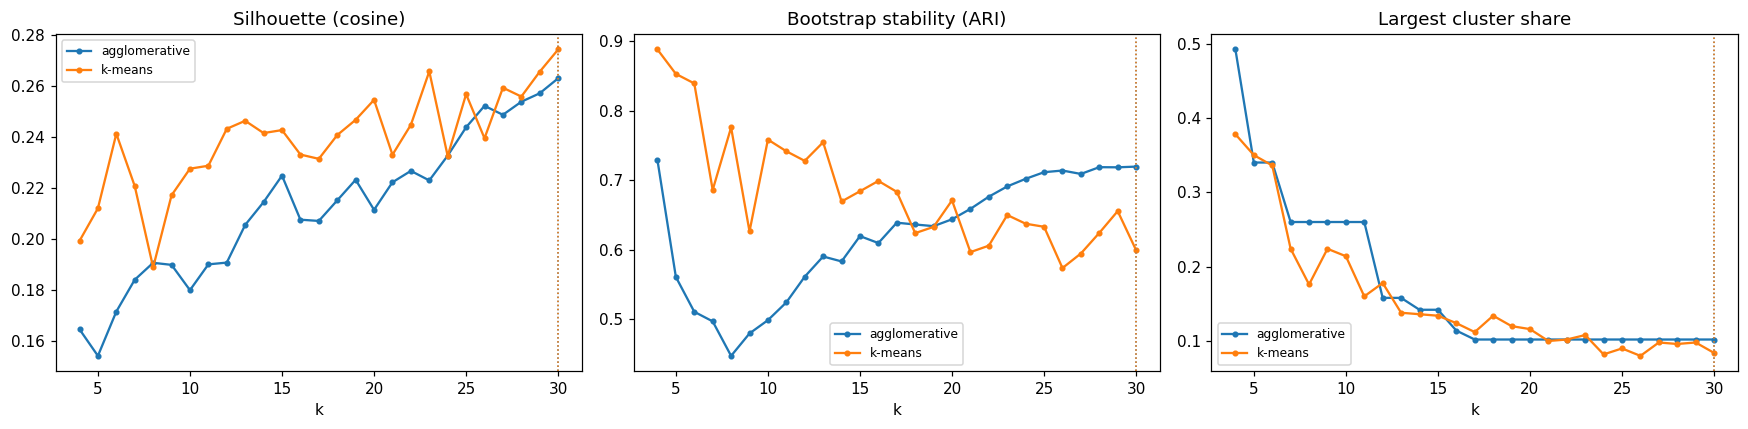

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for method_name, part in k_table.query("representation == @MAIN_REP").groupby("method"):
    axes[0].plot(part["k"], part["silhouette"], marker=".", label=method_name)
    axes[1].plot(part["k"], part["stability_ari"], marker=".", label=method_name)
    axes[2].plot(part["k"], part["largest_cluster_share"], marker=".", label=method_name)
for ax, title in zip(axes, ["Silhouette (cosine)", "Bootstrap stability (ARI)", "Largest cluster share"]):
    ax.axvline(K_KM, color="C0", ls=":", lw=1)
    ax.axvline(K_AG, color="C1", ls=":", lw=1)
    ax.set(xlabel="k", title=title)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. After clustering: seriousness and time

Only now is the outcome loaded. For each k-means cluster: the share of cases (known outcome, non-mass) that list at
least one of its drugs and involve hospitalization or death. A cluster whose rate is far from the overall rate groups
drugs with an unusually severe or mild reporting profile, which the clustering found **without** seeing the outcome.
The time plot shows each cluster's share of cases per quarter.

overall serious rate (non-mass cases): 0.264


,n_cases,serious_rate,lift,n_drugs,label
cluster,,,,,
21,97251,0.002,0.006,4,SKIN BURNING SENSATION / ACNE / SKIN IRRITATION
20,119151,0.051,0.195,6,DEVICE EXPULSION / COMPLICATION OF DEVICE REMOVAL / PRODUCT ADHESION ISSUE
11,73834,0.085,0.322,10,PRODUCT DELIVERY MECHANISM ISSUE / EYE IRRITATION / DRUG INEFFECTIVE
6,173992,0.099,0.376,13,INJECTION SITE PRURITUS / INJECTION SITE RASH / INJECTION SITE PAIN
29,165500,0.104,0.393,12,DRUG INEFFECTIVE / OFF LABEL USE / DIZZINESS
25,158250,0.134,0.510,9,DRUG DOSE OMISSION BY DEVICE / DEVICE MECHANICAL ISSUE / DEVICE DELIVERY SYSTEM ISSUE
12,69879,0.149,0.564,6,SKELETAL INJURY / BONE LOSS / BONE DENSITY DECREASED
17,398130,0.164,0.623,16,DIARRHOEA / DRUG INEFFECTIVE / NAUSEA
16,1689683,0.176,0.668,36,NEEDLE ISSUE / DRUG INEFFECTIVE / INJECTION SITE PAIN


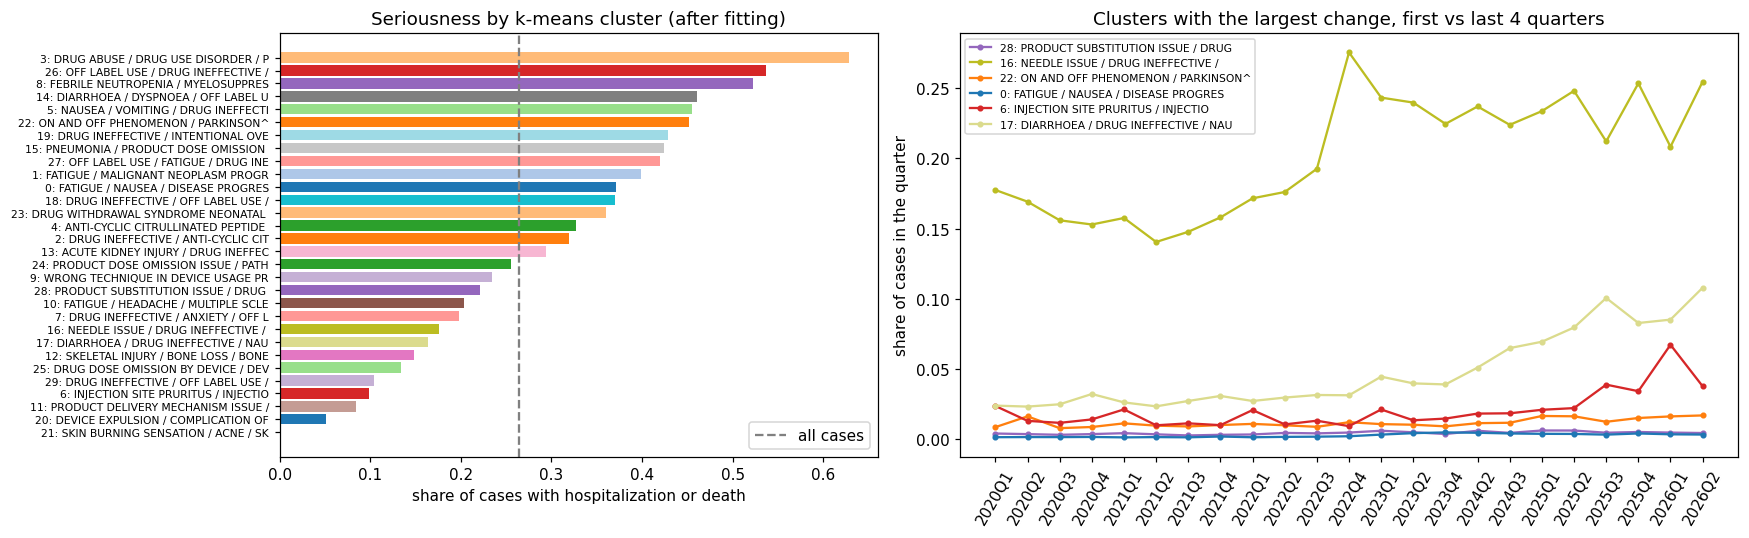

In [15]:
outcome = pd.read_parquet(CLEAN_DIR / "reports_clean.parquet", columns=["safetyreportid", "y_hosp_or_death"])
outcome = outcome.set_index("safetyreportid")["y_hosp_or_death"].astype("float32")
drug_cluster = pd.Series(km_labels, index=np.arange(N_DRUGS))
case_cluster = ing[ing["d"] < N_DRUGS].assign(cluster=lambda t: drug_cluster.reindex(t["d"]).to_numpy())
case_cluster = case_cluster[["safetyreportid", "cluster"]].drop_duplicates()
case_cluster["y"] = outcome.reindex(case_cluster["safetyreportid"]).to_numpy()
case_cluster["quarter"] = cases.set_index("safetyreportid")["quarter"].reindex(case_cluster["safetyreportid"]).to_numpy()

base_rate = outcome.reindex(keep_ids).mean()
seriousness = case_cluster.groupby("cluster")["y"].agg(n_cases="size", serious_rate="mean")
seriousness["lift"] = seriousness["serious_rate"] / base_rate
seriousness = seriousness.join(km_profile.set_index("cluster")[["n_drugs", "label"]]).sort_values("serious_rate")
seriousness.to_csv(TABLE_DIR / "unsup_cluster_seriousness.csv")
print(f"overall serious rate (non-mass cases): {base_rate:.3f}")
display(seriousness.round(3))

quarter_totals = cases.loc[~cases["is_mass_report"]].groupby("quarter", observed=True).size()
prevalence = (case_cluster.groupby(["quarter", "cluster"], observed=True).size().unstack(fill_value=0)
              .div(quarter_totals, axis=0))
prevalence.to_csv(TABLE_DIR / "unsup_cluster_prevalence_by_quarter.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh([f"{c}: {lab[:34]}" for c, lab in zip(seriousness.index, seriousness["label"])], seriousness["serious_rate"],
             color=[cmap(c % 20) for c in seriousness.index])
axes[0].axvline(base_rate, color="grey", ls="--", label="all cases")
axes[0].set(xlabel="share of cases with hospitalization or death", title="Seriousness by k-means cluster (after fitting)")
axes[0].tick_params(axis="y", labelsize=7)
axes[0].legend()
growth = prevalence.iloc[-4:].mean() / prevalence.iloc[:4].mean()
for c in growth.abs().sort_values().index[-6:]:
    axes[1].plot(prevalence.index.astype(str), prevalence[c], marker=".", color=cmap(c % 20),
                 label=f"{c}: {km_profile.set_index('cluster').loc[c, 'label'][:34]}")
axes[1].set(ylabel="share of cases in the quarter", title="Clusters with the largest change, first vs last 4 quarters")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_seriousness_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Sensitivity analysis (k-means on TF-IDF)

How much do the clusters change when one choice changes? Agreement with the main solution is measured by ARI on the
drugs both solutions contain.

1. **k** (section 5 curves): silhouette and stability as k moves around the chosen value.
2. **Random seed:** 10 seeds.
3. **SVD dimensions:** 10, 25, 50, 100, and no reduction.
4. **Vocabulary:** 300 or 800 drugs; 500 or 2,000 reaction terms.
5. **Case weighting:** plain counts instead of the 1 / n_drugs weight.
6. **k:** two and four clusters either side of the chosen value.

In [16]:
sens_rows = []
for seed in range(10):
    sens_rows.append({"experiment": "random seed", "setting": seed,
                      "ari_vs_main": adjusted_rand_score(km_labels, kmeans_labels(Z, K_KM, seed=seed + 1))})
for dims in (10, 25, 50, 100, None):
    Zd = normalize(tfidf) if dims is None else embed(tfidf, dims)[0]
    labels = kmeans_labels(Zd, K_KM)
    sens_rows.append({"experiment": "SVD dimensions", "setting": dims or "none",
                      "ari_vs_main": adjusted_rand_score(km_labels, labels), **cluster_quality(Zd, labels)})
for n_d, n_r in ((300, 1000), (800, 1000), (500, 500), (500, 2000)):
    Zv = embed(tfidf_rep(counts_full[:n_d, :n_r].astype(float)))[0]
    labels = kmeans_labels(Zv, K_KM)
    shared = min(n_d, N_DRUGS)
    sens_rows.append({"experiment": "vocabulary", "setting": f"{n_d} drugs x {n_r} reactions",
                      "ari_vs_main": adjusted_rand_score(km_labels[:shared], labels[:shared]), **cluster_quality(Zv, labels)})
Zraw = embed(tfidf_rep(raw_counts_full[:N_DRUGS, :N_REACTIONS]))[0]
labels = kmeans_labels(Zraw, K_KM)
sens_rows.append({"experiment": "case weighting", "setting": "plain counts (no 1/n_drugs weight)",
                  "ari_vs_main": adjusted_rand_score(km_labels, labels), **cluster_quality(Zraw, labels)})
for k in (K_KM - 4, K_KM - 2, K_KM + 2, K_KM + 4):
    labels = kmeans_labels(Z, k)
    sens_rows.append({"experiment": "k", "setting": k, "ari_vs_main": adjusted_rand_score(km_labels, labels),
                      **cluster_quality(Z, labels)})

sensitivity = pd.DataFrame(sens_rows)
sensitivity["setting"] = sensitivity["setting"].astype(str)
sensitivity.to_csv(TABLE_DIR / "unsup_sensitivity.csv", index=False)
display(sensitivity.groupby("experiment", sort=False)["ari_vs_main"].agg(["mean", "min", "max"]).round(3))
display(sensitivity.query("experiment != 'random seed'").round(3))

,mean,min,max
experiment,,,
random seed,0.594,0.524,0.676
SVD dimensions,0.631,0.467,1.000
vocabulary,0.568,0.537,0.612
case weighting,0.445,0.445,0.445
k,0.618,0.596,0.638


,experiment,setting,ari_vs_main,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,n_tiny_clusters,size_entropy
10,SVD dimensions,10,0.467,0.354,1.286,68.506,0.100,0.0,0.947
11,SVD dimensions,25,0.598,0.307,1.464,39.470,0.086,0.0,0.950
12,SVD dimensions,50,1.000,0.274,1.560,28.367,0.084,0.0,0.944
13,SVD dimensions,100,0.604,0.214,1.784,21.755,0.090,2.0,0.940
14,SVD dimensions,none,0.487,0.152,2.010,15.975,0.088,2.0,0.919
15,vocabulary,300 drugs x 1000 reactions,0.552,0.307,1.452,19.711,0.103,3.0,0.910
16,vocabulary,800 drugs x 1000 reactions,0.571,0.224,1.732,38.142,0.070,0.0,0.951
17,vocabulary,500 drugs x 500 reactions,0.612,0.245,1.615,28.648,0.094,1.0,0.941
18,vocabulary,500 drugs x 2000 reactions,0.537,0.280,1.602,27.227,0.080,0.0,0.952
19,case weighting,plain counts (no 1/n_drugs weight),0.445,0.268,1.604,29.392,0.114,0.0,0.925


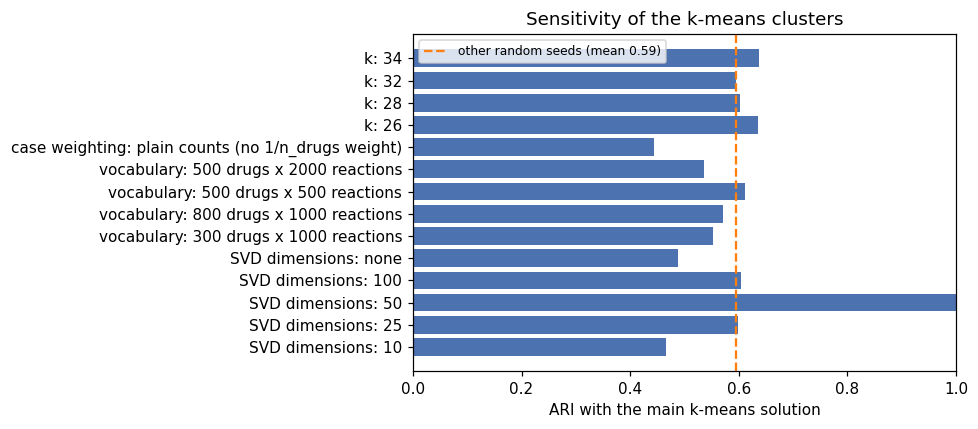

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = sensitivity.query("experiment != 'random seed'")
ax.barh([f"{e}: {s}" for e, s in zip(plot["experiment"], plot["setting"])], plot["ari_vs_main"], color="#4C72B0")
seed_ari = sensitivity.query("experiment == 'random seed'")["ari_vs_main"]
ax.axvline(seed_ari.mean(), color="C1", ls="--", label=f"other random seeds (mean {seed_ari.mean():.2f})")
ax.set(xlabel="ARI with the main k-means solution", xlim=(0, 1), title="Sensitivity of the k-means clusters")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "unsup_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Save

One row per drug: its case count, k-means and agglomerative cluster, and the cluster label. Notebook 7 uses this
table to tag newly scored cases with the safety-profile clusters of their suspect drugs.

In [18]:
labels_by_cluster = km_profile.set_index("cluster")["label"]
drug_clusters = pd.DataFrame({"ingredient": drugs, "n_cases": n_cases_per_drug, "kmeans_cluster": km_labels,
                              "agglomerative_cluster": ag_labels,
                              "kmeans_label": labels_by_cluster.reindex(km_labels).to_numpy(),
                              "umap_x": layout[:, 0], "umap_y": layout[:, 1]})
drug_clusters.to_parquet(OUT_DIR / "drug_clusters.parquet", index=False)
pd.DataFrame(counts.astype("float32"), index=drugs, columns=reaction_names).to_parquet(OUT_DIR / "drug_reaction_counts.parquet")
print("saved", OUT_DIR / "drug_clusters.parquet", drug_clusters.shape)
display(drug_clusters.sort_values("n_cases", ascending=False).head(15))

saved /Users/suvidhinikhil/Data science projects/Milestone 2 projects/FAERS_Milestone2_Final/data/unsupervised/drug_clusters.parquet (500, 7)


,ingredient,n_cases,kmeans_cluster,agglomerative_cluster,kmeans_label,umap_x,umap_y
0,DUPILUMAB,400248,16,0,NEEDLE ISSUE / DRUG INEFFECTIVE / INJECTION SITE PAIN,7.780304,6.360645
1,RANITIDINE,320851,13,6,ACUTE KIDNEY INJURY / DRUG INEFFECTIVE / DIZZINESS,7.525170,2.687245
2,ADALIMUMAB,236868,16,6,NEEDLE ISSUE / DRUG INEFFECTIVE / INJECTION SITE PAIN,7.693092,5.808066
3,LENALIDOMIDE,202564,27,5,OFF LABEL USE / FATIGUE / DRUG INEFFECTIVE,4.923946,4.183038
4,ACETAMINOPHEN,184777,23,4,DRUG WITHDRAWAL SYNDROME NEONATAL / DEPENDENCE / LEARNING DISABILITY,12.929419,5.111813
5,OXYCODONE,164259,23,4,DRUG WITHDRAWAL SYNDROME NEONATAL / DEPENDENCE / LEARNING DISABILITY,13.092510,5.365110
6,METHOTREXATE,136843,2,3,DRUG INEFFECTIVE / ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE / OFF LABEL USE,7.827924,4.880204
7,TIRZEPATIDE,126259,17,0,DIARRHOEA / DRUG INEFFECTIVE / NAUSEA,7.481838,7.035057
8,RITUXIMAB,115055,2,3,DRUG INEFFECTIVE / ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE / OFF LABEL USE,7.882242,4.794497
9,PREDNISONE,102423,2,3,DRUG INEFFECTIVE / ANTI-CYCLIC CITRULLINATED PEPTIDE ANTIBODY POSITIVE / OFF LABEL USE,7.874225,4.680635


## Summary

The numbers in the written report are read from `reports/tables/unsup_*.csv`. Main points:

- Splitting each case's evidence among its suspect drugs matters most: plain counts let ~4,600 templated reports
  define the profile of every common drug they list (ARI only 0.45 between weighted and plain-count clusters).
- With TF-IDF profiles, k-means (k = 30) and Ward clustering (k = 30) find clinically readable groups: injectable
  biologics (needle and injection-site problems), GLP-1 agonists and insulins, opioids (dependence, neonatal
  withdrawal), psychiatric drugs (intentional overdose), cytotoxic chemotherapy (myelosuppression), oral oncology,
  inhalers (device technique), contraceptive implants and IUDs, HIV antiretrovirals, Parkinson's drugs, ADHD
  stimulants (product substitution), antibiotics, ophthalmics, IV and dialysis fluids, substances of abuse.
  The two methods agree moderately (ARI 0.56).
- Stability is moderate (k-means bootstrap ARI about 0.57, Ward about 0.72): the distinctive groups are stable,
  while drugs on the border between general "drug ineffective / off-label" clusters move between runs.
- Without seeing the outcome, the clusters separate seriousness from 0.2% (topical acne and sunscreen products)
  to 63% (substances of abuse); chemotherapy, antibiotics and Parkinson's drugs are all above 45%.
- Over time, the GLP-1/insulin cluster grew from about 3% to 9% of cases and injectable biologics from 16% to 23%,
  while the ranitidine-led cluster fell from 10% to 5% as litigation reports faded.